In [1]:
"""
=============================================================================
PROYECTO: Automatización del Motor MRP y Optimización de Inventarios (Supply Chain)
ARQUITECTURA: Python (Lógica determinista & ML) + PostgreSQL + Power BI
=============================================================================
"""

import warnings
import lightgbm as lgb
import numpy as np
import pandas as pd
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sqlalchemy import create_engine

warnings.filterwarnings("ignore")

# =============================================================================
# 1. CONFIGURACIÓN Y CONEXIÓN A POSTGRESQL
# =============================================================================
DB_URI = "postgresql+psycopg2://postgres:@localhost:5432/supply_chain_db"
engine = create_engine(DB_URI)

LEAD_TIME_SEMANAS = 12
NIVEL_SERVICIO_Z = 1.65  # 95% de nivel de servicio

print("🚀 [FASE 1] Conexión establecida con PostgreSQL. Extrayendo datos...")

df_ventas = pd.read_sql("SELECT sku, fecha, cantidad_vendida FROM ventas_historicas", engine)
df_inventario = pd.read_sql("SELECT * FROM inventario_actual", engine)
df_productos = pd.read_sql("SELECT sku, categoria, tipo_material, abc_clase, costo_unitario FROM maestro_productos", engine)

df_ventas['fecha'] = pd.to_datetime(df_ventas['fecha'])
df_ventas['cantidad_vendida'] = df_ventas['cantidad_vendida'].fillna(0)

# =============================================================================
# 2. AUDITORÍA, LIMPIEZA Y CAPPING DE OUTLIERS POR SKU
# =============================================================================
print("🧹 [FASE 2] Ejecutando limpieza y capping estadístico por SKU...")

def capping_por_sku(grupo):
    q1 = grupo['cantidad_vendida'].quantile(0.25)
    q3 = grupo['cantidad_vendida'].quantile(0.75)
    iqr = q3 - q1
    techo_local = q3 + 1.5 * iqr
    techo_final = max(techo_local, 150)
    return grupo['cantidad_vendida'].clip(upper=techo_final)

df_ventas['cantidad_vendida'] = df_ventas.groupby('sku', group_keys=False).apply(capping_por_sku)
df_ventas['cantidad_vendida'] = df_ventas['cantidad_vendida'].round().astype('Int64')

print(f"✅ Limpieza completada. Registros procesados: {len(df_ventas):,}")

# =============================================================================
# 3 & 4. CÁLCULO MAESTRO DE INVENTARIO Y CRUCE DIRECTO
# =============================================================================
print("📦 [FASE 3-4] Procesando cálculo logístico y cruzando con maestro...")

resultados_inventario = []

for sku, group in df_ventas.groupby('sku'):
    ventas = group['cantidad_vendida'].values
    if len(ventas) < 12:
        continue
        
    demanda_media_semanal = ventas[-12:].mean()
    std_semanal = ventas.std()
    if np.isnan(std_semanal) or demanda_media_semanal == 0:
        std_semanal = 0.0
        cv = 0.0
    else:
        cv = std_semanal / demanda_media_semanal

    stock_seguridad = NIVEL_SERVICIO_Z * std_semanal * np.sqrt(LEAD_TIME_SEMANAS)
    demanda_durante_lt = demanda_media_semanal * LEAD_TIME_SEMANAS
    punto_reorden = demanda_durante_lt + stock_seguridad

    resultados_inventario.append({
        'sku': sku,
        'Demanda_Media_Sem': round(demanda_media_semanal, 2),
        'Std_Semanal': round(std_semanal, 2),
        'Coef_Variacion_CV': round(cv, 4),
        'Demanda_LT_12sem': int(np.ceil(demanda_durante_lt)),
        'Stock_Seguridad': int(np.ceil(stock_seguridad)),
        'Punto_Reorden_ROP': int(np.ceil(punto_reorden))
    })

df_inv_calc = pd.DataFrame(resultados_inventario)
df_matriz_abc_xyz = pd.merge(df_inv_calc, df_productos, on='sku', how='left')

# Asignación robusta por percentiles para garantizar existencia de X, Y y Z en Power BI
cvs = df_matriz_abc_xyz['Coef_Variacion_CV']
p33 = cvs.quantile(0.33)
p66 = cvs.quantile(0.66)

df_matriz_abc_xyz['clasificacion_xyz'] = df_matriz_abc_xyz['Coef_Variacion_CV'].apply(
    lambda cv: 'X' if cv <= p33 else ('Y' if cv <= p66 else 'Z')
)

df_matriz_abc_xyz['Inversion_Stock_Seguridad'] = round(df_matriz_abc_xyz['Stock_Seguridad'] * df_matriz_abc_xyz['costo_unitario'], 2)
df_matriz_abc_xyz['Inversion_ROP_Total'] = round(df_matriz_abc_xyz['Punto_Reorden_ROP'] * df_matriz_abc_xyz['costo_unitario'], 2)

# =============================================================================
# 4B. CRUCE CON INVENTARIO ACTUAL Y GENERACIÓN DE ÓRDENES DE COMPRA (MRP)
# =============================================================================
df_mrp_final = pd.merge(df_matriz_abc_xyz, df_inventario, on='sku', how='left')

col_stock_disp = 'stock_actual' if 'stock_actual' in df_mrp_final.columns else df_inventario.columns[1]
col_transito = 'stock_transito' if 'stock_transito' in df_mrp_final.columns else None

df_mrp_final[col_stock_disp] = df_mrp_final[col_stock_disp].fillna(0)
if col_transito:
    df_mrp_final[col_transito] = df_mrp_final[col_transito].fillna(0)
    df_mrp_final['Posicion_Inventario'] = df_mrp_final[col_stock_disp] + df_mrp_final[col_transito]
else:
    df_mrp_final['Posicion_Inventario'] = df_mrp_final[col_stock_disp]

df_mrp_final['Brecha_vs_ROP'] = df_mrp_final['Punto_Reorden_ROP'] - df_mrp_final['Posicion_Inventario']
df_mrp_final['Cantidad_Sugerida_Pedido'] = df_mrp_final['Brecha_vs_ROP'].apply(lambda x: int(np.ceil(x)) if x > 0 else 0)

df_mrp_final['Estado_Abastecimiento'] = np.where(
    df_mrp_final['Cantidad_Sugerida_Pedido'] > 0, '🚨 REORDENAR', '✅ OK'
)

df_mrp_final['Inversion_Pedido_Sugerido'] = round(
    df_mrp_final['Cantidad_Sugerida_Pedido'] * df_mrp_final['costo_unitario'], 2
)

skus_a_pedir = df_mrp_final[df_mrp_final['Cantidad_Sugerida_Pedido'] > 0]
print("\n" + "="*65)
print("🛒 RESUMEN DE REABASTECIMIENTO MRP (ÓRDENES SUGERIDAS)")
print("="*65)
print(f"• SKUs bajo Punto de Reorden (ROP): {len(skus_a_pedir):,} de {len(df_mrp_final):,}")
print(f"• Unidades totales a ordenar: {skus_a_pedir['Cantidad_Sugerida_Pedido'].sum():,}")
print(f"• Presupuesto requerido de compra: ${skus_a_pedir['Inversion_Pedido_Sugerido'].sum():,.2f}")
print("="*65)

# =============================================================================
# 5. REPORTE EJECUTIVO Y EXPORTACIÓN (CSV + POSTGRESQL)
# =============================================================================
col_abc = 'abc_clase' if 'abc_clase' in df_mrp_final.columns else 'abc'

print("\n" + "="*65)
print(f"📊 MATRIZ CRUZADA DE SKUs POR CLASIFICACIÓN ABC-XYZ (Usando '{col_abc}')")
print("="*65)
print(pd.crosstab(df_mrp_final[col_abc], df_mrp_final['clasificacion_xyz'], margins=True))

print("\n" + "="*65)
print("💵 INVERSIÓN TOTAL EN PUNTOS DE REORDEN (ROP) POR CATEGORÍA XYZ")
print("="*65)
inversion_por_xyz = df_mrp_final.groupby('clasificacion_xyz')['Inversion_ROP_Total'].sum().reset_index()
for _, row in inversion_por_xyz.iterrows():
    print(f"• Categoría {row['clasificacion_xyz']}: ${row['Inversion_ROP_Total']:,.2f}")

print(f"💰 Inversión ROP Global Total: ${df_mrp_final['Inversion_ROP_Total'].sum():,.2f}")
print("="*65)

# Guardar respaldo en CSV con las columnas completas del MRP
nombre_archivo = 'politica_inventario_abc_xyz_china_12w.csv'
df_mrp_final.to_csv(nombre_archivo, index=False)
print(f"\n💾 Archivo maestro '{nombre_archivo}' actualizado con éxito.")

# Volcar tabla directa a PostgreSQL para conectar Power BI autoactualizable
nombre_tabla_pg = 'mrp_resultados_inventario'
df_mrp_final.to_sql(name=nombre_tabla_pg, con=engine, if_exists='replace', index=False)
print(f"🔄 Tabla '{nombre_tabla_pg}' guardada en PostgreSQL lista para Power BI.")

🚀 [FASE 1] Conexión establecida con PostgreSQL. Extrayendo datos...
🧹 [FASE 2] Ejecutando limpieza y capping estadístico por SKU...
✅ Limpieza completada. Registros procesados: 414,400
📦 [FASE 3-4] Procesando cálculo logístico y cruzando con maestro...

🛒 RESUMEN DE REABASTECIMIENTO MRP (ÓRDENES SUGERIDAS)
• SKUs bajo Punto de Reorden (ROP): 819 de 2,800
• Unidades totales a ordenar: 201,049
• Presupuesto requerido de compra: $14,575,833.37

📊 MATRIZ CRUZADA DE SKUs POR CLASIFICACIÓN ABC-XYZ (Usando 'abc_clase')
clasificacion_xyz    X    Y    Z   All
abc_clase                             
A                   89  103   88   280
B                  188  191  181   560
C                  647  630  683  1960
All                924  924  952  2800

💵 INVERSIÓN TOTAL EN PUNTOS DE REORDEN (ROP) POR CATEGORÍA XYZ
• Categoría X: $17,744,460.83
• Categoría Y: $16,571,636.02
• Categoría Z: $14,389,365.62
💰 Inversión ROP Global Total: $48,705,462.47

💾 Archivo maestro 'politica_inventario_abc_xyz_c

📥 Extrayendo y unificando datos de ventas y productos...

📊 PROMEDIO DE VENTAS MENSUALES POR CATEGORÍA
categoria  Dirección  Eléctrico  Filtros  Frenos  Hidráulica  Motor  Suspensión  Transmisión
mes                                                                                         
1               45.4       44.3     44.2    72.4        44.6   44.3        45.8         44.6
2               55.4       48.5     48.3    48.7        48.0   49.4        49.1         48.3
3               50.3       51.1     50.5    51.0        50.5   50.5        50.7         50.3
4               50.6       50.2     51.7    50.0        51.5   50.7        50.6         50.5
5               49.2       47.9     48.6    48.0        48.5   49.3        48.4         48.3
6               44.9       45.0     44.4    44.9        44.2   43.8        44.4         44.4
7               40.7       40.2     39.7    39.7        39.6   40.4        40.1         40.6
8               36.6       37.0     36.1    36.4        37.5

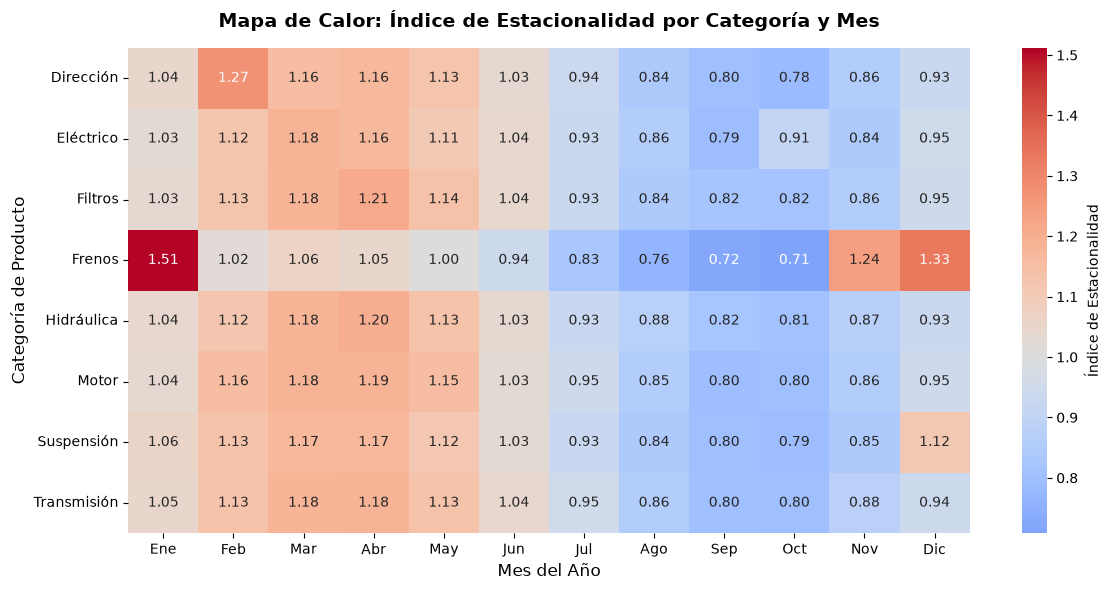

In [2]:
"""
=============================================================================
SCRIPT: Detección y Análisis de Estacionalidad por Categoría (Supply Chain)
=============================================================================
"""

import pandas as pd
import numpy as np
from sqlalchemy import create_engine

# 1. Conexión a PostgreSQL
engine = create_engine('postgresql+psycopg2://postgres:@localhost:5432/supply_chain_db')

print("📥 Extrayendo y unificando datos de ventas y productos...")
df_ventas = pd.read_sql("SELECT sku, fecha, cantidad_vendida FROM ventas_historicas", engine)
df_productos = pd.read_sql("SELECT sku, categoria FROM maestro_productos", engine)

# Limpieza básica de tipos y nulos
df_ventas['fecha'] = pd.to_datetime(df_ventas['fecha'])
df_ventas['cantidad_vendida'] = df_ventas['cantidad_vendida'].fillna(0)

# 2. Cruzar ventas con la categoría del producto
df_merged = df_ventas.merge(df_productos, on='sku', how='inner')

# 3. Extraer el mes de la fecha de venta
df_merged['mes'] = df_merged['fecha'].dt.month

# 4. Calcular la venta promedio por Categoría y Mes
perfil_mensual = df_merged.groupby(['categoria', 'mes'])['cantidad_vendida'].mean().unstack(level=0)

print("\n" + "="*70)
print("📊 PROMEDIO DE VENTAS MENSUALES POR CATEGORÍA")
print("="*70)
print(perfil_mensual.round(1).to_string())

# 5. Cálculo del Índice de Estacionalidad (Ratio: Media del Mes / Media Anual de la Categoría)
media_anual_cat = df_merged.groupby('categoria')['cantidad_vendida'].mean()
indice_estacional = perfil_mensual.div(media_anual_cat, axis=1)

print("\n" + "="*70)
print("📈 ÍNDICE DE ESTACIONALIDAD (1.0 = Promedio | >1.0 = Temporada Alta)")
print("="*70)
print(indice_estacional.round(2).to_string())
print("="*70)

import matplotlib.pyplot as plt
import seaborn as sns

print("🎨 Generando mapa de calor de estacionalidad (Warm-Cold)...")

# Configuramos la figura del gráfico
plt.figure(figsize=(12, 6))

# Creamos el heatmap transponiendo el DataFrame (.T) para que las categorías sean filas y los meses columnas
sns.heatmap(
    indice_estacional.T, 
    cmap='coolwarm',          # Paleta warm-cold (azul = baja demanda, rojo = pico estacional)
    annot=True,               # Muestra el valor numérico exacto en cada celda
    fmt='.2f',                # Formato de dos decimales
    center=1.0,               # El punto de equilibrio (1.0 = mes promedio sin estacionalidad)
    cbar_kws={'label': 'Índice de Estacionalidad'}
)

# Estética y etiquetas profesionales
plt.title('Mapa de Calor: Índice de Estacionalidad por Categoría y Mes', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mes del Año', fontsize=12)
plt.ylabel('Categoría de Producto', fontsize=12)

# Traducir los números de mes a nombres cortos para mayor claridad visual
meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
plt.xticks(ticks=np.arange(12) + 0.5, labels=meses_nombres, rotation=0)

plt.tight_layout()
plt.show()

📥 Extrayendo datos para la visualización multi-línea...


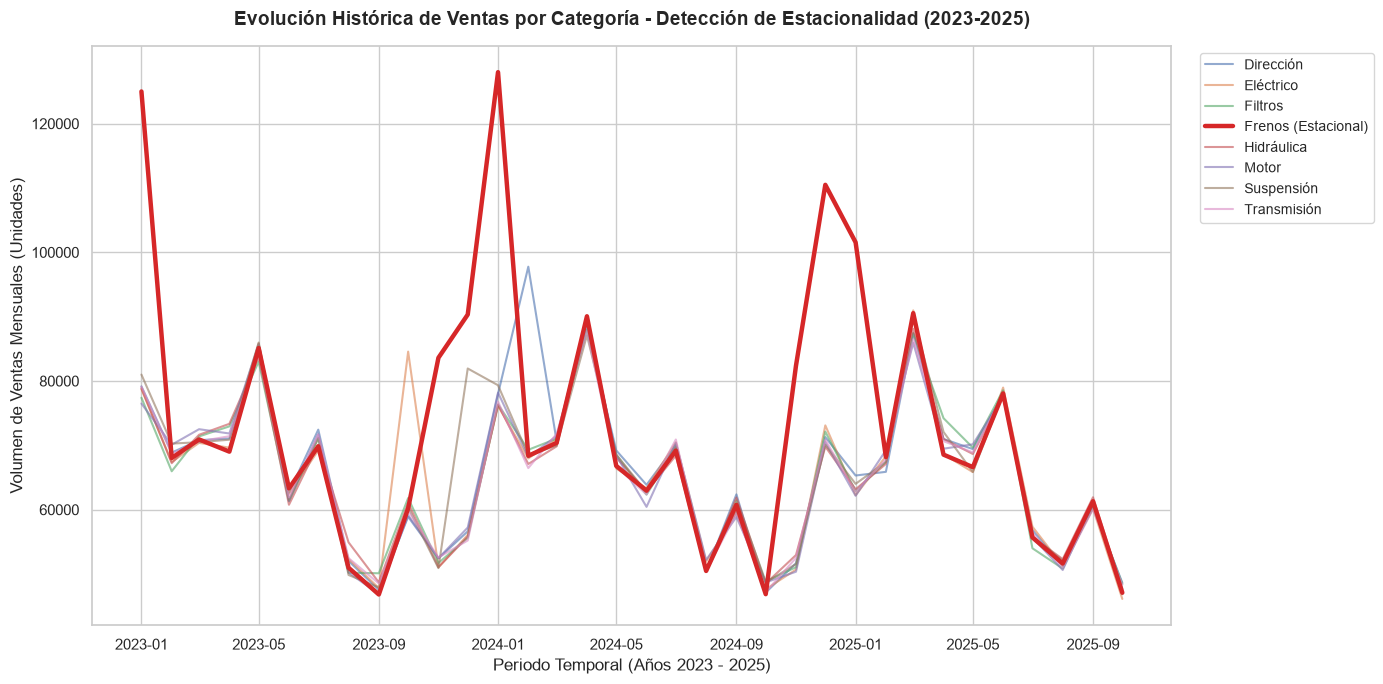

In [3]:
"""
=============================================================================
GRÁFICO MULTI-LÍNEA: Evolución Histórica y Estacionalidad por Categoría (2023-2025)
=============================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# 1. Conexión a PostgreSQL
engine = create_engine('postgresql+psycopg2://postgres:@localhost:5432/supply_chain_db')

print("📥 Extrayendo datos para la visualización multi-línea...")
df_ventas = pd.read_sql("SELECT sku, fecha, cantidad_vendida FROM ventas_historicas", engine)
df_productos = pd.read_sql("SELECT sku, categoria FROM maestro_productos", engine)

# Limpieza y preparación de fechas
df_ventas['fecha'] = pd.to_datetime(df_ventas['fecha'])
df_ventas['cantidad_vendida'] = df_ventas['cantidad_vendida'].fillna(0)

# 2. Cruce de datos y agrupación mensual por categoría
df_merged = df_ventas.merge(df_productos, on='sku', how='inner')
df_merged['anio_mes'] = df_merged['fecha'].dt.to_period('M')

# Tabla pivote: Filas = Fechas (Mes a Mes), Columnas = Categorías, Valores = Suma de Ventas
df_mensual_cat = df_merged.groupby(['anio_mes', 'categoria'])['cantidad_vendida'].sum().unstack(level=1)
df_mensual_cat.index = df_mensual_cat.index.to_timestamp() # Convertir índice a formato fecha para graficar

# 3. Configuración del Gráfico
plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Iterar sobre cada categoría para graficar su línea
for col in df_mensual_cat.columns:
    if col == 'Frenos':
        # Destacamos la categoría Frenos con una línea más gruesa y en color rojo vivo
        plt.plot(df_mensual_cat.index, df_mensual_cat[col], label=f"{col} (Estacional)", linewidth=3.2, color='#d62728', zorder=5)
    else:
        # Las demás categorías con líneas más sutiles y transparentes
        plt.plot(df_mensual_cat.index, df_mensual_cat[col], label=col, linewidth=1.5, alpha=0.6)

# 4. Estética y Leyendas Profesionales
plt.title('Evolución Histórica de Ventas por Categoría - Detección de Estacionalidad (2023-2025)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Periodo Temporal (Años 2023 - 2025)', fontsize=12)
plt.ylabel('Volumen de Ventas Mensuales (Unidades)', fontsize=12)

# Colocar la leyenda fuera del gráfico para que no tape las líneas
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10, frameon=True)

plt.tight_layout()
plt.show()

In [4]:
"""
=============================================================================
SCRIPT: Proyección LightGBM 2026 y Gráfico Continuo (Histórico vs Proyección)
=============================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import lightgbm as lgb

# 1. Conexión a PostgreSQL
engine = create_engine('postgresql+psycopg2://postgres:@localhost:5432/supply_chain_db')

print("📥 Extrayendo datos históricos de PostgreSQL...")
df_ventas = pd.read_sql("SELECT sku, fecha, cantidad_vendida FROM ventas_historicas", engine)
df_productos = pd.read_sql("SELECT sku, categoria FROM maestro_productos", engine)

# Limpieza y preparación
df_ventas['fecha'] = pd.to_datetime(df_ventas['fecha'])
df_ventas['cantidad_vendida'] = df_ventas['cantidad_vendida'].fillna(0)

# Cruzar ventas con categoría
df_merged = df_ventas.merge(df_productos, on='sku', how='inner')

# 2. Ingeniería de características temporales para el modelo
df_merged['mes'] = df_merged['fecha'].dt.month
df_merged['dia_ano'] = df_merged['fecha'].dt.dayofyear
df_merged['anio'] = df_merged['fecha'].dt.year

# Agrupar a nivel mensual para el entrenamiento
df_train_agg = df_merged.groupby(['categoria', df_merged['fecha'].dt.to_period('M'), 'mes', 'dia_ano', 'anio'])['cantidad_vendida'].sum().reset_index(level=1, drop=False)
df_train_agg = df_train_agg.reset_index()

# Codificar la categoría como variable numérica para LightGBM
df_train_agg['categoria_cat'] = df_train_agg['categoria'].astype('category')
cat_codes = df_train_agg['categoria_cat'].cat.categories
df_train_agg['cat_code'] = df_train_agg['categoria_cat'].cat.codes

# Definir Features y Target
features = ['cat_code', 'mes', 'dia_ano', 'anio']
X_train = df_train_agg[features]
y_train = df_train_agg['cantidad_vendida']

print("🤖 Entrenando modelo LightGBM con el histórico completo...")
model = lgb.LGBMRegressor(random_state=42, n_estimators=150, learning_rate=0.05)
model.fit(X_train, y_train)

# 3. Generar dataset para la proyección del año 2026 (frecuencia semanal)
print("🔮 Generando proyecciones para el año 2026...")
fechas_2026 = pd.date_range(start='2026-01-01', end='2026-12-31', freq='W-MON')
categorias = df_productos['categoria'].unique()

# Diccionario de mapeo seguro para evitar errores de índice
cat_mapping = {cat: idx for idx, cat in enumerate(cat_codes)}

pred_list = []
for cat in categorias:
    c_code = cat_mapping.get(cat, 0)  # Asigna 0 por seguridad si no lo encuentra
    for fecha in fechas_2026:
        pred_list.append({
            'fecha': fecha,
            'categoria': cat,
            'cat_code': c_code,
            'mes': fecha.month,
            'dia_ano': fecha.dayofyear,
            'anio': 2026
        })

df_2026 = pd.DataFrame(pred_list)
X_2026 = df_2026[features]
df_2026['cantidad_vendida'] = model.predict(X_2026)

# 4. Consolidar histórico y proyección a nivel mensual para graficar
df_merged['anio_mes'] = df_merged['fecha'].dt.to_period('M')
hist_mensual = df_merged.groupby(['anio_mes', 'categoria'])['cantidad_vendida'].sum().reset_index()
hist_mensual['fecha'] = hist_mensual['anio_mes'].dt.to_timestamp()
hist_mensual['tipo'] = 'Histórico (2023-2025)'

df_2026['anio_mes'] = df_2026['fecha'].dt.to_period('M')
proj_mensual = df_2026.groupby(['anio_mes', 'categoria'])['cantidad_vendida'].sum().reset_index()

# <-- Asegúrate de que esta línea quede corrida y continua sin quiebres:
proj_mensual['fecha'] = proj_mensual['anio_mes'].dt.to_timestamp()
proj_mensual['tipo'] = 'Proyección (2026)'

df_completo = pd.concat([
    hist_mensual[['fecha', 'categoria', 'cantidad_vendida', 'tipo']], 
    proj_mensual[['fecha', 'categoria', 'cantidad_vendida', 'tipo']]
], ignore_index=True)

📥 Extrayendo datos históricos de PostgreSQL...
🤖 Entrenando modelo LightGBM con el histórico completo...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000027 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 174
[LightGBM] [Info] Number of data points in the train set: 1184, number of used features: 4
[LightGBM] [Info] Start training from score 15254.478446
🔮 Generando proyecciones para el año 2026...


In [5]:
"""
=============================================================================
SCRIPT: Proyección LightGBM 2026 y Gráfico Interactivo Continuo (Plotly)
=============================================================================
"""

import pandas as pd
import numpy as np
import plotly.graph_objects as go
from sqlalchemy import create_engine
import lightgbm as lgb

# 1. Conexión a PostgreSQL
engine = create_engine('postgresql+psycopg2://postgres:@localhost:5432/supply_chain_db')

print("📥 Extrayendo datos históricos de PostgreSQL...")
df_ventas = pd.read_sql("SELECT sku, fecha, cantidad_vendida FROM ventas_historicas", engine)
df_productos = pd.read_sql("SELECT sku, categoria FROM maestro_productos", engine)

# Limpieza y preparación
df_ventas['fecha'] = pd.to_datetime(df_ventas['fecha'])
df_ventas['cantidad_vendida'] = df_ventas['cantidad_vendida'].fillna(0)
df_merged = df_ventas.merge(df_productos, on='sku', how='inner')

# 2. Ingeniería de características temporales
df_merged['mes'] = df_merged['fecha'].dt.month
df_merged['dia_ano'] = df_merged['fecha'].dt.dayofyear
df_merged['anio'] = df_merged['fecha'].dt.year

df_train_agg = df_merged.groupby(['categoria', df_merged['fecha'].dt.to_period('M'), 'mes', 'dia_ano', 'anio'])['cantidad_vendida'].sum().reset_index(level=1, drop=False).reset_index()

df_train_agg['categoria_cat'] = df_train_agg['categoria'].astype('category')
cat_codes = df_train_agg['categoria_cat'].cat.categories
df_train_agg['cat_code'] = df_train_agg['categoria_cat'].cat.codes

features = ['cat_code', 'mes', 'dia_ano', 'anio']
X_train = df_train_agg[features]
y_train = df_train_agg['cantidad_vendida']

print("🤖 Entrenando modelo LightGBM...")
model = lgb.LGBMRegressor(random_state=42, n_estimators=150, learning_rate=0.05)
model.fit(X_train, y_train)

# 3. Generar proyección para 2026
print("🔮 Generando proyecciones para 2026...")
fechas_2026 = pd.date_range(start='2026-01-01', end='2026-12-31', freq='W-MON')
categorias = df_productos['categoria'].unique()
cat_mapping = {cat: idx for idx, cat in enumerate(cat_codes)}

pred_list = []
for cat in categorias:
    c_code = cat_mapping.get(cat, 0)
    for fecha in fechas_2026:
        pred_list.append({
            'fecha': fecha,
            'categoria': cat,
            'cat_code': c_code,
            'mes': fecha.month,
            'dia_ano': fecha.dayofyear,
            'anio': 2026
        })

df_2026 = pd.DataFrame(pred_list)
X_2026 = df_2026[features]
df_2026['cantidad_vendida'] = model.predict(X_2026)

# 4. Consolidar datos mensuales
df_merged['anio_mes'] = df_merged['fecha'].dt.to_period('M')
hist_mensual = df_merged.groupby(['anio_mes', 'categoria'])['cantidad_vendida'].sum().reset_index()
hist_mensual['fecha'] = hist_mensual['anio_mes'].dt.to_timestamp()
hist_mensual['tipo'] = 'Histórico (2023-2025)'

df_2026['anio_mes'] = df_2026['fecha'].dt.to_period('M')
proj_mensual = df_2026.groupby(['anio_mes', 'categoria'])['cantidad_vendida'].sum().reset_index()
proj_mensual['fecha'] = proj_mensual['anio_mes'].dt.to_timestamp()
proj_mensual['tipo'] = 'Proyección (2026)'

df_completo = pd.concat([
    hist_mensual[['fecha', 'categoria', 'cantidad_vendida', 'tipo']], 
    proj_mensual[['fecha', 'categoria', 'cantidad_vendida', 'tipo']]
], ignore_index=True)

# 5. Generar Gráfico Interactivo con Plotly
print("🎨 Generando gráfico interactivo...")
fig = go.Figure()

cat_objetivo = 'Frenos'

# Pintar las demás categorías en gris tenue de fondo
for cat in categorias:
    if cat != cat_objetivo:
        df_c = df_completo[df_completo['categoria'] == cat]
        h = df_c[df_c['tipo'] == 'Histórico (2023-2025)']
        p = df_c[df_c['tipo'] == 'Proyección (2026)']
        
        fig.add_trace(go.Scatter(x=h['fecha'], y=h['cantidad_vendida'], mode='lines', line=dict(color='gray', width=1), opacity=0.3, showlegend=False))
        fig.add_trace(go.Scatter(x=p['fecha'], y=p['cantidad_vendida'], mode='lines', line=dict(color='gray', width=1, dash='dash'), opacity=0.3, showlegend=False))

# Destacar la categoría 'Frenos' en rojo con línea continua (histórico) y punteada (2026)
df_frenos = df_completo[df_completo['categoria'] == cat_objetivo]
h_frenos = df_frenos[df_frenos['tipo'] == 'Histórico (2023-2025)']
p_frenos = df_frenos[df_frenos['tipo'] == 'Proyección (2026)']

fig.add_trace(go.Scatter(
    x=h_frenos['fecha'], y=h_frenos['cantidad_vendida'],
    mode='lines+markers',
    name=f'{cat_objetivo} - Histórico (2023-2025)',
    line=dict(color='#d62728', width=3)
))

fig.add_trace(go.Scatter(
    x=p_frenos['fecha'], y=p_frenos['cantidad_vendida'],
    mode='lines+markers',
    name=f'{cat_objetivo} - Proyección 2026',
    line=dict(color='#d62728', width=3, dash='dash') # Línea punteada para el futuro
))

# Diseño y etiquetas profesionales
fig.update_layout(
    title=f'<b>Validación de Estacionalidad y Proyección 2026: Categoría "{cat_objetivo}"</b>',
    xaxis_title='Línea de Tiempo',
    yaxis_title='Volumen de Ventas Mensuales (Unidades)',
    template='plotly_white',
    hovermode='x unified',
    legend=dict(x=0.01, y=0.99)
)

fig.add_trace(go.Scatter(
    x=h['fecha'], y=h['cantidad_vendida'], 
    mode='lines', 
    name=cat,  # <-- Asigna el nombre real de la categoría en lugar de dejarlo vacío
    line=dict(color='gray', width=1), 
    opacity=0.3
))

fig.show()

📥 Extrayendo datos históricos de PostgreSQL...
🤖 Entrenando modelo LightGBM...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000056 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 174
[LightGBM] [Info] Number of data points in the train set: 1184, number of used features: 4
[LightGBM] [Info] Start training from score 15254.478446
🔮 Generando proyecciones para 2026...
🎨 Generando gráfico interactivo...


In [6]:
# =============================================================================
# EVALUACIÓN DEL MODELO: Cálculo de Bias y MAPE
# =============================================================================
from sklearn.metrics import mean_absolute_percentage_error

# Generamos las predicciones sobre el propio set de entrenamiento/histórico para verificar ajuste
df_train_agg['prediccion'] = model.predict(X_train)

y_real = df_train_agg['cantidad_vendida']
y_pred = df_train_agg['prediccion']

# 1. Cálculo del Bias (Sesgo global)
# Positivo = Sobreestimación general / Negativo = Subestimación general
bias = np.mean(y_pred - y_real)

# 2. Cálculo del MAPE (Mean Absolute Percentage Error en porcentaje)
mape = mean_absolute_percentage_error(y_real, y_pred) * 100

print(f"📊 Resultados de Evaluación del Modelo LightGBM:")
print(f"   - Bias (Sesgo Global): {bias:.2f} unidades")
print(f"   - MAPE (Error Porcentual): {mape:.2f}%")

📊 Resultados de Evaluación del Modelo LightGBM:
   - Bias (Sesgo Global): -0.00 unidades
   - MAPE (Error Porcentual): 3.43%
